In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("restaurant_food_wastage_dataset_v2.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Shape: (20000, 11)

Columns:
['Date', 'Outlet_ID', 'Product_ID', 'Quantity_Prepared', 'Quantity_Sold', 'Quantity_Discarded', 'Weather', 'Weekday', 'Holiday', 'Promotion', 'Special_Event']

Missing values:
Date                  0
Outlet_ID             0
Product_ID            0
Quantity_Prepared     0
Quantity_Sold         0
Quantity_Discarded    0
Weather               0
Weekday               0
Holiday               0
Promotion             0
Special_Event         0
dtype: int64

Duplicate rows: 0

Data types:
Date                  object
Outlet_ID             object
Product_ID            object
Quantity_Prepared      int64
Quantity_Sold          int64
Quantity_Discarded     int64
Weather               object
Weekday               object
Holiday                int64
Promotion              int64
Special_Event          int64
dtype: object


In [2]:
print("Negative quantities:")
print((df[["Quantity_Prepared", "Quantity_Sold", "Quantity_Discarded"]] < 0).sum())

print("\nPrepared < Sold:")
print((df["Quantity_Prepared"] < df["Quantity_Sold"]).sum())

print("\nInvalid wastage calculation:")
print(
    (df["Quantity_Prepared"] -
     df["Quantity_Sold"] !=
     df["Quantity_Discarded"]).sum()
)

Negative quantities:
Quantity_Prepared     0
Quantity_Sold         0
Quantity_Discarded    0
dtype: int64

Prepared < Sold:
0

Invalid wastage calculation:
0


In [3]:
df["Wastage_Percentage"] = (
    df["Quantity_Discarded"] /
    df["Quantity_Prepared"]
) * 100

df[[
    "Product_ID",
    "Quantity_Prepared",
    "Quantity_Sold",
    "Quantity_Discarded",
    "Wastage_Percentage"
]].head(10)

,Product_ID,Quantity_Prepared,Quantity_Sold,Quantity_Discarded,Wastage_Percentage
0,P015,133,107,26,19.548872
1,P015,87,83,4,4.597701
2,P007,69,69,0,0.000000
3,P017,131,112,19,14.503817
4,P018,56,54,2,3.571429
5,P003,83,79,4,4.819277
6,P005,112,104,8,7.142857
7,P005,155,137,18,11.612903
8,P010,107,94,13,12.149533
9,P024,121,110,11,9.090909


In [5]:
overall_wastage = (
    df["Quantity_Discarded"].sum() /
    df["Quantity_Prepared"].sum()
) * 100

print(f"Overall Wastage Percentage: {overall_wastage:.2f}%")

Overall Wastage Percentage: 12.23%


In [6]:
product_wastage = (
    df.groupby("Product_ID")
    .agg(
        Total_Prepared=("Quantity_Prepared", "sum"),
        Total_Sold=("Quantity_Sold", "sum"),
        Total_Discarded=("Quantity_Discarded", "sum")
    )
)

product_wastage["Wastage_Percentage"] = (
    product_wastage["Total_Discarded"] /
    product_wastage["Total_Prepared"]
) * 100

product_wastage = product_wastage.sort_values(
    "Wastage_Percentage",
    ascending=False
)

product_wastage.head(10)

,Total_Prepared,Total_Sold,Total_Discarded,Wastage_Percentage
Product_ID,,,,
P027,97817,78645,19172,19.599865
P004,87480,70494,16986,19.417010
P014,90258,72793,17465,19.350085
P009,86882,70080,16802,19.338873
P021,57849,47108,10741,18.567305
P005,98282,86937,11345,11.543314
P023,76433,67737,8696,11.377285
P006,103376,91635,11741,11.357568
P029,101191,89702,11489,11.353777


In [7]:
promotion_analysis = (
    df.groupby("Promotion")
    .agg(
        Total_Prepared=("Quantity_Prepared", "sum"),
        Total_Sold=("Quantity_Sold", "sum"),
        Total_Discarded=("Quantity_Discarded", "sum")
    )
)

promotion_analysis["Wastage_Percentage"] = (
    promotion_analysis["Total_Discarded"] /
    promotion_analysis["Total_Prepared"]
) * 100

promotion_analysis

,Total_Prepared,Total_Sold,Total_Discarded,Wastage_Percentage
Promotion,,,,
0,1322305,1191749,130556,9.873365
1,898206,757095,141111,15.710316


In [9]:
no_promo = promotion_analysis.loc[0, "Wastage_Percentage"]
promo = promotion_analysis.loc[1, "Wastage_Percentage"]

print(f"No Promotion: {no_promo:.2f}%")
print(f"Promotion: {promo:.2f}%")
print(f"Difference: {promo - no_promo:.2f} percentage points")

No Promotion: 9.87%
Promotion: 15.71%
Difference: 5.84 percentage points


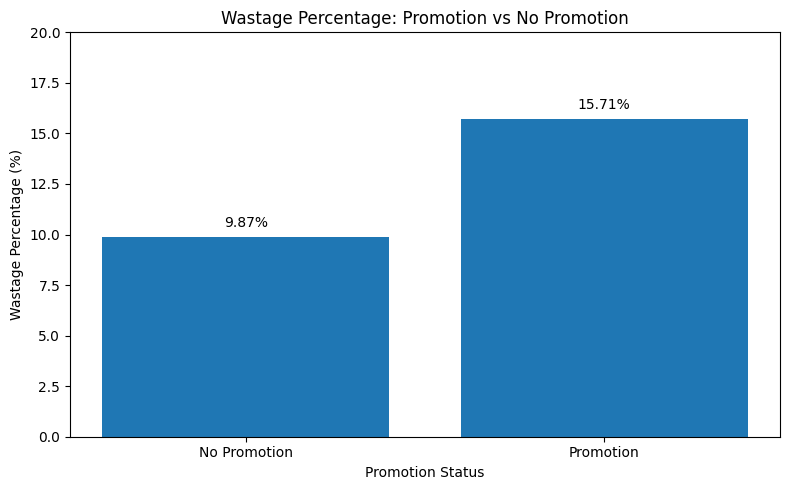

In [10]:
import matplotlib.pyplot as plt

plot_data = promotion_analysis.reset_index()
plot_data["Promotion_Label"] = plot_data["Promotion"].map({
    0: "No Promotion",
    1: "Promotion"
})

plt.figure(figsize=(8, 5))
plt.bar(
    plot_data["Promotion_Label"],
    plot_data["Wastage_Percentage"]
)

plt.title("Wastage Percentage: Promotion vs No Promotion")
plt.xlabel("Promotion Status")
plt.ylabel("Wastage Percentage (%)")
plt.ylim(0, 20)

for i, value in enumerate(plot_data["Wastage_Percentage"]):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [11]:
df["Day_Type"] = np.where(
    df["Weekday"].isin(["Saturday", "Sunday"]),
    "Weekend",
    "Weekday"
)

day_analysis = (
    df.groupby("Day_Type")
    .agg(
        Total_Prepared=("Quantity_Prepared", "sum"),
        Total_Sold=("Quantity_Sold", "sum"),
        Total_Discarded=("Quantity_Discarded", "sum")
    )
)

day_analysis["Wastage_Percentage"] = (
    day_analysis["Total_Discarded"] /
    day_analysis["Total_Prepared"]
) * 100

day_analysis

,Total_Prepared,Total_Sold,Total_Discarded,Wastage_Percentage
Day_Type,,,,
Weekday,1460735,1283412,177323,12.139300
Weekend,759776,665432,94344,12.417344


In [12]:
weather_analysis = (
    df.groupby("Weather")
    .agg(
        Total_Prepared=("Quantity_Prepared", "sum"),
        Total_Sold=("Quantity_Sold", "sum"),
        Total_Discarded=("Quantity_Discarded", "sum")
    )
)

weather_analysis["Wastage_Percentage"] = (
    weather_analysis["Total_Discarded"] /
    weather_analysis["Total_Prepared"]
) * 100

weather_analysis.sort_values(
    "Wastage_Percentage",
    ascending=False
)

,Total_Prepared,Total_Sold,Total_Discarded,Wastage_Percentage
Weather,,,,
Stormy,135002,113119,21883,16.209389
Cloudy,593084,521539,71545,12.063215
Sunny,1024279,901900,122379,11.947819
Rainy,468146,412286,55860,11.932175


In [14]:
event_analysis = (
    df.groupby("Special_Event")
    .agg(
        Total_Prepared=("Quantity_Prepared", "sum"),
        Total_Sold=("Quantity_Sold", "sum"),
        Total_Discarded=("Quantity_Discarded", "sum")
    )
)

event_analysis["Wastage_Percentage"] = (
    event_analysis["Total_Discarded"] /
    event_analysis["Total_Prepared"]
) * 100

event_analysis

,Total_Prepared,Total_Sold,Total_Discarded,Wastage_Percentage
Special_Event,,,,
0,2083569,1837733,245836,11.798793
1,136942,111111,25831,18.862730


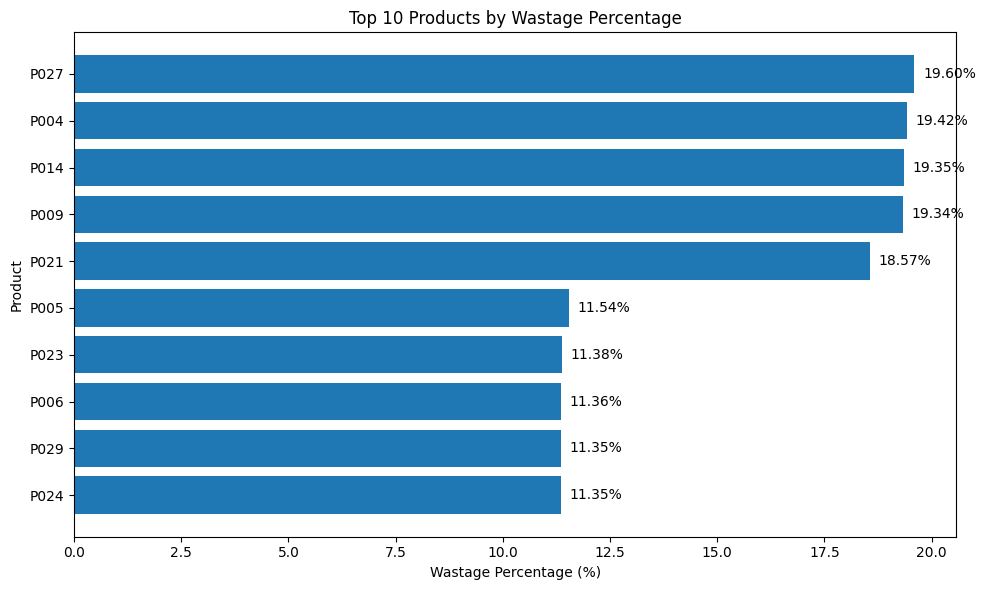

In [15]:
top_products = product_wastage.head(10).reset_index()

plt.figure(figsize=(10, 6))

plt.barh(
    top_products["Product_ID"],
    top_products["Wastage_Percentage"]
)

plt.xlabel("Wastage Percentage (%)")
plt.ylabel("Product")
plt.title("Top 10 Products by Wastage Percentage")
plt.gca().invert_yaxis()

for i, value in enumerate(top_products["Wastage_Percentage"]):
    plt.text(value + 0.2, i, f"{value:.2f}%", va="center")

plt.tight_layout()
plt.show()

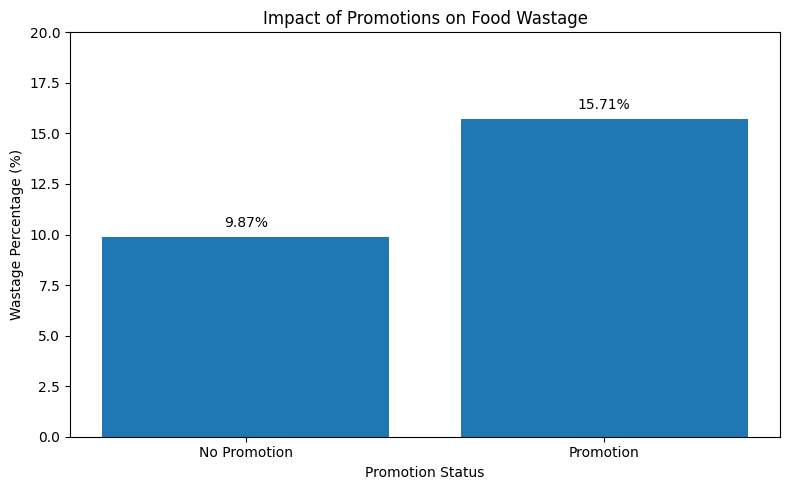

In [16]:
plt.figure(figsize=(8, 5))

labels = ["No Promotion", "Promotion"]
values = [
    promotion_analysis.loc[0, "Wastage_Percentage"],
    promotion_analysis.loc[1, "Wastage_Percentage"]
]

plt.bar(labels, values)

plt.title("Impact of Promotions on Food Wastage")
plt.xlabel("Promotion Status")
plt.ylabel("Wastage Percentage (%)")
plt.ylim(0, 20)

for i, value in enumerate(values):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

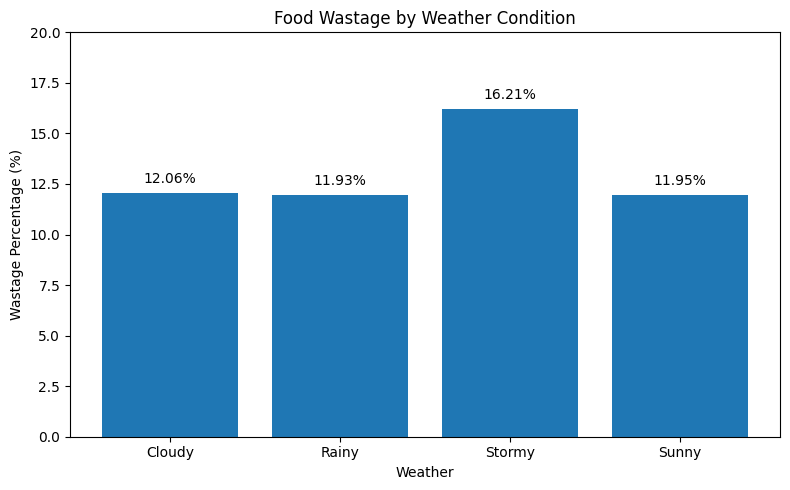

In [17]:
weather_plot = weather_analysis.reset_index()

plt.figure(figsize=(8, 5))

plt.bar(
    weather_plot["Weather"],
    weather_plot["Wastage_Percentage"]
)

plt.title("Food Wastage by Weather Condition")
plt.xlabel("Weather")
plt.ylabel("Wastage Percentage (%)")
plt.ylim(0, 20)

for i, value in enumerate(weather_plot["Wastage_Percentage"]):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

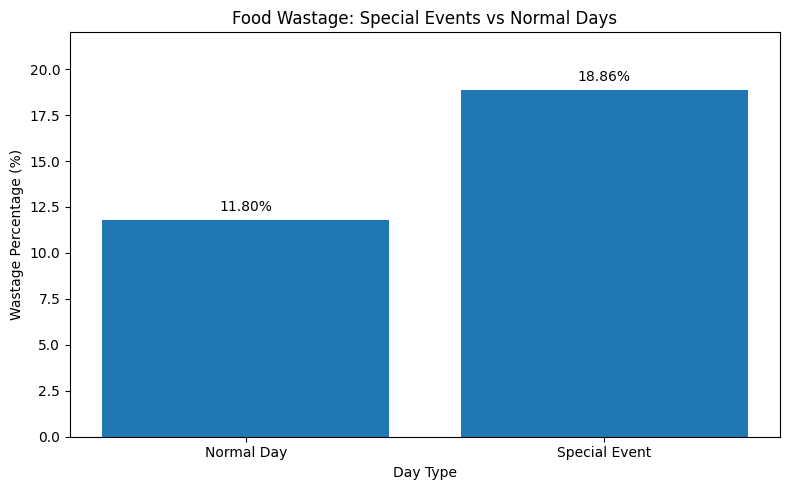

In [18]:
event_plot = event_analysis.reset_index()

event_plot["Event_Type"] = event_plot["Special_Event"].map({
    0: "Normal Day",
    1: "Special Event"
})

plt.figure(figsize=(8, 5))

plt.bar(
    event_plot["Event_Type"],
    event_plot["Wastage_Percentage"]
)

plt.title("Food Wastage: Special Events vs Normal Days")
plt.xlabel("Day Type")
plt.ylabel("Wastage Percentage (%)")
plt.ylim(0, 22)

for i, value in enumerate(event_plot["Wastage_Percentage"]):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model_df = df.copy()

model_df["Date"] = pd.to_datetime(model_df["Date"])

model_df["Year"] = model_df["Date"].dt.year
model_df["Month"] = model_df["Date"].dt.month
model_df["Day"] = model_df["Date"].dt.day

model_df = pd.get_dummies(
    model_df,
    columns=[
        "Outlet_ID",
        "Product_ID",
        "Weather",
        "Weekday"
    ],
    drop_first=True
)

X = model_df.drop(
    columns=[
        "Date",
        "Quantity_Sold",
        "Quantity_Prepared",
        "Quantity_Discarded",
        "Wastage_Percentage",
        "Day_Type"
    ],
    errors="ignore"
)

y = model_df["Quantity_Sold"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (20000, 63)
Target: (20000,)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

print("Model training completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Model training completed!
Training samples: 16000
Testing samples: 4000


In [21]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

MAE  : 17.97
RMSE : 23.06
R²   : 0.6798


In [22]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
42,Product_ID_P019,0.095752
40,Product_ID_P017,0.089856
38,Product_ID_P015,0.052333
29,Product_ID_P006,0.052189
52,Product_ID_P029,0.051878
28,Product_ID_P005,0.051836
34,Product_ID_P011,0.051756
33,Product_ID_P010,0.047145
49,Product_ID_P026,0.045213
58,Weekday_Saturday,0.042335


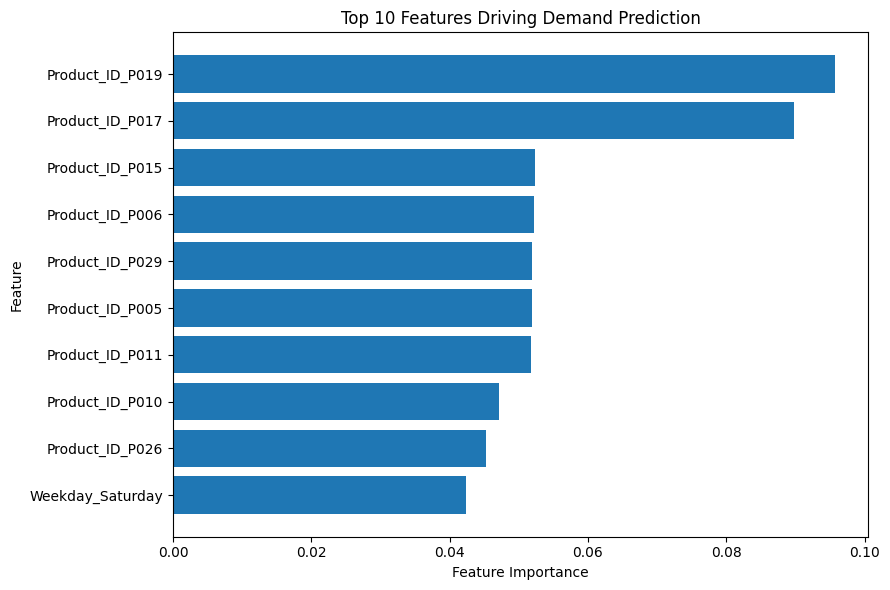

In [23]:
top_features = feature_importance.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Features Driving Demand Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [24]:
forecast_test = X_test.copy()

forecast_test["Actual_Sold"] = y_test.values
forecast_test["Predicted_Demand"] = y_pred

forecast_test[["Actual_Sold", "Predicted_Demand"]].head(10)

,Actual_Sold,Predicted_Demand
10650,73,73.814079
2041,83,73.567026
8668,43,69.634591
1114,51,70.531951
13902,91,89.954189
11963,50,69.572800
11072,110,143.102914
3002,119,123.619117
19771,50,73.667913
8115,99,108.625054


In [25]:
actual_prepared = df.loc[X_test.index, "Quantity_Prepared"].values

forecast_test["Actual_Prepared"] = actual_prepared

forecast_test["Recommended_Preparation"] = np.ceil(
    forecast_test["Predicted_Demand"] * 1.10
)

forecast_test["Forecast_Wastage"] = np.maximum(
    forecast_test["Recommended_Preparation"] -
    forecast_test["Actual_Sold"],
    0
)

forecast_test.head(10)

,Holiday,Promotion,Special_Event,Year,Month,Day,Outlet_ID_OUT002,Outlet_ID_OUT003,Outlet_ID_OUT004,Outlet_ID_OUT005,...,Weekday_Saturday,Weekday_Sunday,Weekday_Thursday,Weekday_Tuesday,Weekday_Wednesday,Actual_Sold,Predicted_Demand,Actual_Prepared,Recommended_Preparation,Forecast_Wastage
10650,0,1,0,2026,1,22,False,False,False,True,...,False,False,True,False,False,73,73.814079,87,82.0,9.0
2041,0,0,0,2025,3,15,False,False,False,False,...,True,False,False,False,False,83,73.567026,99,81.0,0.0
8668,0,0,0,2025,11,12,False,False,False,False,...,False,False,False,False,True,43,69.634591,44,77.0,34.0
1114,0,0,0,2025,2,10,False,True,False,False,...,False,False,False,False,False,51,70.531951,53,78.0,27.0
13902,0,0,0,2026,5,21,False,False,False,False,...,False,False,True,False,False,91,89.954189,98,99.0,8.0
11963,0,0,0,2026,3,10,False,False,False,False,...,False,False,False,True,False,50,69.572800,52,77.0,27.0
11072,0,1,0,2026,2,6,False,False,False,False,...,False,False,False,False,False,110,143.102914,128,158.0,48.0
3002,0,0,0,2025,4,19,False,False,False,False,...,True,False,False,False,False,119,123.619117,126,136.0,17.0
19771,0,1,0,2026,12,23,False,False,False,False,...,False,False,False,False,True,50,73.667913,54,82.0,32.0
8115,0,0,0,2025,10,24,False,False,False,False,...,False,False,False,False,False,99,108.625054,117,120.0,21.0


In [26]:
baseline_wastage = (
    (forecast_test["Actual_Prepared"] - forecast_test["Actual_Sold"]).sum()
    / forecast_test["Actual_Prepared"].sum()
) * 100

forecast_wastage = (
    forecast_test["Forecast_Wastage"].sum()
    / forecast_test["Recommended_Preparation"].sum()
) * 100

shortage_units = np.maximum(
    forecast_test["Actual_Sold"] -
    forecast_test["Recommended_Preparation"],
    0
).sum()

shortage_rate = (
    shortage_units /
    forecast_test["Actual_Sold"].sum()
) * 100

print(f"Actual preparation wastage : {baseline_wastage:.2f}%")
print(f"Forecast-guided wastage    : {forecast_wastage:.2f}%")
print(f"Wastage reduction          : {baseline_wastage - forecast_wastage:.2f} percentage points")
print(f"Shortage units             : {shortage_units:.0f}")
print(f"Shortage rate              : {shortage_rate:.2f}%")

Actual preparation wastage : 12.23%
Forecast-guided wastage    : 13.98%
Wastage reduction          : -1.76 percentage points
Shortage units             : 21066
Shortage rate              : 5.35%


In [27]:
buffer_results = []

for buffer in [0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:

    recommended = np.ceil(
        forecast_test["Predicted_Demand"] * (1 + buffer)
    )

    wastage = np.maximum(
        recommended - forecast_test["Actual_Sold"],
        0
    )

    shortage = np.maximum(
        forecast_test["Actual_Sold"] - recommended,
        0
    )

    wastage_pct = (
        wastage.sum() / recommended.sum()
    ) * 100

    shortage_pct = (
        shortage.sum() / forecast_test["Actual_Sold"].sum()
    ) * 100

    buffer_results.append([
        f"{buffer * 100:.0f}%",
        wastage_pct,
        shortage_pct
    ])

buffer_df = pd.DataFrame(
    buffer_results,
    columns=["Safety Buffer", "Wastage %", "Shortage %"]
)

buffer_df

,Safety Buffer,Wastage %,Shortage %
0,0%,9.201579,9.091972
1,5%,11.562026,6.969427
2,10%,13.983481,5.353630
3,15%,16.609246,4.039493
4,20%,19.197101,3.046583
5,25%,21.826985,2.301710
6,30%,24.438169,1.734479


In [28]:
!pip install -q streamlit plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 44.6 MB/s eta 0:00:00


In [29]:
%%writefile restaurant_dashboard.py

import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(
    page_title="Restaurant Food Wastage Analytics",
    page_icon="🍽️",
    layout="wide"
)

df = pd.read_csv("restaurant_food_wastage_dataset_v2.csv")

df["Date"] = pd.to_datetime(df["Date"])

df["Wastage_Percentage"] = (
    df["Quantity_Discarded"] / df["Quantity_Prepared"]
) * 100

st.title("🍽️ Restaurant Food Wastage Analytics")
st.caption("Food wastage analysis, demand patterns and operational insights")

st.sidebar.header("Filters")

outlet = st.sidebar.multiselect(
    "Outlet",
    sorted(df["Outlet_ID"].unique()),
    default=sorted(df["Outlet_ID"].unique())
)

weather = st.sidebar.multiselect(
    "Weather",
    sorted(df["Weather"].unique()),
    default=sorted(df["Weather"].unique())
)

promotion = st.sidebar.multiselect(
    "Promotion",
    sorted(df["Promotion"].unique()),
    default=sorted(df["Promotion"].unique())
)

filtered_df = df[
    (df["Outlet_ID"].isin(outlet)) &
    (df["Weather"].isin(weather)) &
    (df["Promotion"].isin(promotion))
]

total_prepared = filtered_df["Quantity_Prepared"].sum()
total_discarded = filtered_df["Quantity_Discarded"].sum()

overall_wastage = (
    total_discarded / total_prepared * 100
    if total_prepared > 0 else 0
)

avg_wastage = filtered_df["Wastage_Percentage"].mean()

high_waste_product = (
    filtered_df.groupby("Product_ID")["Wastage_Percentage"]
    .mean()
    .idxmax()
)

col1, col2, col3, col4 = st.columns(4)

col1.metric("🍱 Food Prepared", f"{total_prepared:,.0f}")
col2.metric("🗑️ Food Discarded", f"{total_discarded:,.0f}")
col3.metric("♻️ Wastage %", f"{overall_wastage:.2f}%")
col4.metric("⚠️ Highest-Waste Product", high_waste_product)

st.divider()

product_waste = (
    filtered_df.groupby("Product_ID")
    .agg(
        Prepared=("Quantity_Prepared", "sum"),
        Discarded=("Quantity_Discarded", "sum")
    )
    .reset_index()
)

product_waste["Wastage %"] = (
    product_waste["Discarded"] /
    product_waste["Prepared"] * 100
)

product_waste = product_waste.sort_values(
    "Wastage %",
    ascending=False
).head(10)

fig1 = px.bar(
    product_waste,
    x="Wastage %",
    y="Product_ID",
    orientation="h",
    title="Top 10 Products by Wastage %",
    text_auto=".2f"
)

fig1.update_layout(yaxis={"categoryorder": "total ascending"})

st.plotly_chart(fig1, use_container_width=True)

col1, col2 = st.columns(2)

promotion_analysis = (
    filtered_df.groupby("Promotion")
    .agg(
        Prepared=("Quantity_Prepared", "sum"),
        Discarded=("Quantity_Discarded", "sum")
    )
    .reset_index()
)

promotion_analysis["Wastage %"] = (
    promotion_analysis["Discarded"] /
    promotion_analysis["Prepared"] * 100
)

fig2 = px.bar(
    promotion_analysis,
    x="Promotion",
    y="Wastage %",
    title="Promotion vs Wastage",
    text_auto=".2f"
)

col1.plotly_chart(fig2, use_container_width=True)

weather_analysis = (
    filtered_df.groupby("Weather")
    .agg(
        Prepared=("Quantity_Prepared", "sum"),
        Discarded=("Quantity_Discarded", "sum")
    )
    .reset_index()
)

weather_analysis["Wastage %"] = (
    weather_analysis["Discarded"] /
    weather_analysis["Prepared"] * 100
)

fig3 = px.bar(
    weather_analysis,
    x="Weather",
    y="Wastage %",
    title="Wastage by Weather",
    text_auto=".2f"
)

col2.plotly_chart(fig3, use_container_width=True)

event_analysis = (
    filtered_df.groupby("Special_Event")
    .agg(
        Prepared=("Quantity_Prepared", "sum"),
        Discarded=("Quantity_Discarded", "sum")
    )
    .reset_index()
)

event_analysis["Wastage %"] = (
    event_analysis["Discarded"] /
    event_analysis["Prepared"] * 100
)

fig4 = px.bar(
    event_analysis,
    x="Special_Event",
    y="Wastage %",
    title="Special Event vs Normal Day",
    text_auto=".2f"
)

st.plotly_chart(fig4, use_container_width=True)

st.subheader("📋 Top Waste-Producing Products")

st.dataframe(
    product_waste,
    use_container_width=True
)

st.subheader("💡 Key Operational Insight")

st.info(
    f"The overall wastage rate for the selected data is "
    f"{overall_wastage:.2f}%. "
    f"{high_waste_product} has the highest observed wastage percentage "
    f"among the selected products."
)

Writing restaurant_dashboard.py


In [30]:
!streamlit run restaurant_dashboard.py &>/content/streamlit.log &

import time
time.sleep(3)

!npx localtunnel --port 8501

⠙⠹⠸⠼⠴Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) Y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴your url is: https://bitter-phones-tap.loca.lt
^C


In [31]:
!cat /content/streamlit.log



2026-09-28 09:50:37.521 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.80.34.48:8501

  Stopping...


In [32]:
!nohup streamlit run restaurant_dashboard.py > /content/streamlit.log 2>&1 &

In [33]:
!cat /content/streamlit.log



2026-09-28 09:54:07.992 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.80.34.48:8501



In [34]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴your url is: https://purple-pots-kiss.loca.lt
^C


In [35]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

In [36]:
!./cloudflared tunnel --url http://localhost:8501

2026-09-28T09:56:26Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-09-28T09:56:26Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-09-28T09:56:30Z INF +--------------------------------------------------------------------------------------------+
2026-09-28T09:56:30Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-09-28T09:56:30Z INF |  https://mission-amy-falling-complement.trycloudflare.

In [38]:
!curl -I http://localhost:8501

curl: (7) Failed to connect to localhost port 8501 after 0 ms: Couldn't connect to server


In [40]:
!pkill -f streamlit || true

^C


In [41]:
!nohup streamlit run restaurant_dashboard.py --server.address 0.0.0.0 --server.port 8501 > /content/streamlit.log 2>&1 &

In [42]:
!curl -I http://localhost:8501


HTTP/1.1 200 OK
date: Mon, 28 Sep 2026 10:10:51 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 7260
last-modified: Mon, 28 Sep 2026 09:47:34 GMT
etag: "5d78b13b97a80e2ca5c75614dee805e1"
cache-control: no-cache



In [ ]:
!./cloudflared tunnel --url http://localhost:8501

2026-09-28T10:11:30Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-09-28T10:11:30Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-09-28T10:11:33Z INF +--------------------------------------------------------------------------------------------+
2026-09-28T10:11:33Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-09-28T10:11:33Z INF |  https://reviewed-appear-nuke-jokes.trycloudflare.com 